# Powering the Planet

Energy production and consumption are among the main drivers of global economic development, but they also have significant environmental consequences.

This project explores the evolution of the global energy system and investigates the relationship between economic growth and CO₂ emissions. Using historical data from Our World in Data, the analysis examines changes in energy sources, regional differences and the environmental impact of economic activity.

The main objectives are:
- To analyze how the global energy mix has changed over time.
- To investigate the relationship between GDP and CO₂ emissions across countries and regions.
- To compare per capita emissions and identify differences in environmental impact.

In [1]:
# Set the working directory to the project root
%cd "C:\Users\Duke\Università\Powering-the-Planet"

C:\Users\Duke\Università\Powering-the-Planet


In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from powering_planet import analysis, plots
from powering_planet.config import (
    ENERGY_DATA_URL,
    CO2_DATA_URL,
    ENERGY_COLUMNS,
    CONTINENTS
)

OVERVIEW

The project uses two datasets from Our World in Data:

- Energy dataset: contains information about global energy production and consumption.
- CO₂ dataset: contains information about CO₂ emissions, GDP and population.

The two datasets are kept separate because they support different parts of the analysis.

In [3]:
# download the dataset from the provided URL and print it to verify it has been downloaded correctly
try:
    df_energy = pd.read_csv(ENERGY_DATA_URL)
    df_co2 = pd.read_csv(CO2_DATA_URL)

    print("Datasets successfully loaded.")

except:
    print("Error loading datasets:")

Datasets successfully loaded.


In [4]:
# Preview the datasets
display(df_energy.head())
display(df_co2.head())
# Check dataset dimensions
print("Energy dataset shape:", df_energy.shape)
print("CO2 dataset shape:", df_co2.shape)

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,...,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Energy dataset shape: (23377, 130)
CO2 dataset shape: (56269, 79)


In [5]:
# print all the columns of the dataframe to have a more clear view of the variables
print(f"These are the {len(df_energy.columns)} columns of the dataframe:")
for col in df_energy.columns:
    print(col)

These are the 130 columns of the dataframe:
country
year
iso_code
population
gdp
biofuel_cons_change_pct
biofuel_cons_change_twh
biofuel_cons_per_capita
biofuel_consumption
biofuel_elec_per_capita
biofuel_electricity
biofuel_share_elec
biofuel_share_energy
carbon_intensity_elec
coal_cons_change_pct
coal_cons_change_twh
coal_cons_per_capita
coal_consumption
coal_elec_per_capita
coal_electricity
coal_prod_change_pct
coal_prod_change_twh
coal_prod_per_capita
coal_production
coal_share_elec
coal_share_energy
electricity_demand
electricity_demand_per_capita
electricity_generation
electricity_share_energy
energy_cons_change_pct
energy_cons_change_twh
energy_per_capita
energy_per_gdp
fossil_cons_change_pct
fossil_cons_change_twh
fossil_elec_per_capita
fossil_electricity
fossil_energy_per_capita
fossil_fuel_consumption
fossil_share_elec
fossil_share_energy
gas_cons_change_pct
gas_cons_change_twh
gas_consumption
gas_elec_per_capita
gas_electricity
gas_energy_per_capita
gas_prod_change_pct
gas_p

In [6]:
#show useful informations on the rows
year_min = df_energy['year'].min()
year_max = df_energy['year'].max()

print(f"The dataset covers the years from {year_min} to {year_max}.")
nations = df_energy['country'].unique()

print(f"There are {len(nations)} different entities (considered nations, continents and groups).Here are the first 15 examples:")
print(nations[:15]) 

The dataset covers the years from 1900 to 2025.
There are 314 different entities (considered nations, continents and groups).Here are the first 15 examples:
<ArrowStringArray>
[      'ASEAN (Ember)',         'Afghanistan',              'Africa',
         'Africa (EI)',        'Africa (EIA)',      'Africa (Ember)',
      'Africa (Shift)',             'Albania',             'Algeria',
      'American Samoa',              'Angola',          'Antarctica',
 'Antigua and Barbuda',           'Argentina',             'Armenia']
Length: 15, dtype: str


MACRO-REGIONAL ANALYSIS OF ENERGY MIX AND RENEWABLE TRANSITION TRENDS

In [7]:
#searching for available macro-regions in the dataset
# Identify available macro-regions
target_regions = ["World"] + CONTINENTS

valid_regions = [
    region for region in target_regions
    if region in df_energy["country"].unique()
]

print("Found regions:", valid_regions)


Found regions: ['World', 'Africa', 'Asia', 'Europe', 'North America', 'Oceania', 'South America']


In [8]:
#search for columns related to energy, electricity and CO2 emissions
#instead of using a for cycle, I am using a list comprehension that has the same exact effectiveness since it is usully considered more elegant
# Search for columns related to energy, electricity and CO2 emissions
energy_columns = [
    col for col in df_energy.columns
    if 'electricity' in col.lower()
    or 'energy' in col.lower()
    or 'co2' in col.lower()
]

print("Energy-related columns:", energy_columns)

Energy-related columns: ['biofuel_electricity', 'biofuel_share_energy', 'coal_electricity', 'coal_share_energy', 'electricity_demand', 'electricity_demand_per_capita', 'electricity_generation', 'electricity_share_energy', 'energy_cons_change_pct', 'energy_cons_change_twh', 'energy_per_capita', 'energy_per_gdp', 'fossil_electricity', 'fossil_energy_per_capita', 'fossil_share_energy', 'gas_electricity', 'gas_energy_per_capita', 'gas_share_energy', 'hydro_electricity', 'hydro_energy_per_capita', 'hydro_share_energy', 'low_carbon_electricity', 'low_carbon_energy_per_capita', 'low_carbon_share_energy', 'nuclear_electricity', 'nuclear_energy_per_capita', 'nuclear_share_energy', 'oil_electricity', 'oil_energy_per_capita', 'oil_share_energy', 'other_renewable_electricity', 'other_renewable_exc_biofuel_electricity', 'other_renewables_energy_per_capita', 'other_renewables_share_energy', 'per_capita_electricity', 'primary_energy_consumption', 'renewables_electricity', 'renewables_energy_per_capit

Now we are going to see how the global mix of energy sources changed from 1950 to 2022

We focus on five indicators representing the main sources of primary energy consumption:

- Coal
- Oil
- Natural gas
- Nuclear energy
- Renewables

These variables express each source as a percentage of total primary energy consumption, allowing us to analyse changes in the global energy mix over time.

In [9]:
# Select the main energy sources
mix_columns = ENERGY_COLUMNS.copy()

print("Selected energy variables:", mix_columns)

Selected energy variables: ['coal_share_energy', 'oil_share_energy', 'gas_share_energy', 'nuclear_share_energy', 'renewables_share_energy']


In [10]:
# Check missing values and total energy share
df_world = df_energy[df_energy["country"] == "World"].copy()

df_world = analysis.prepare_world_energy_mix_data(df_world)

print("Missing values:")
print(df_world[ENERGY_COLUMNS].isna().sum())

# Check total energy share for complete observations
df_world_complete = df_world.dropna(subset=ENERGY_COLUMNS)

print("Total energy share outside the expected range:")
print(
    df_world_complete[
        ~df_world_complete["total_share"].between(99.9, 100.1)
    ][["year", "total_share"]]
)

Missing values:
coal_share_energy          66
oil_share_energy           66
gas_share_energy           66
nuclear_share_energy       66
renewables_share_energy    66
dtype: int64
Total energy share outside the expected range:
Empty DataFrame
Columns: [year, total_share]
Index: []


In [11]:
# verify if the 66 missing values for every column, are in the same rows
missing_per_row = df_world[mix_columns].isna().sum(axis=1)

print(missing_per_row.value_counts().sort_index())

0    60
5    66
Name: count, dtype: int64


We can see how the missing values are in the same rows, so it basically means the dataframe has 66 years with missing values that would be excluded from the analysis. Also the variables choice looks like excellent,for the latest years it always sums up to 100%. I am going to verify it more precisely for every year since 4 observations are not enough.

That means there are no rows with a total share out of the range 99,9 - 100,1 in the available years

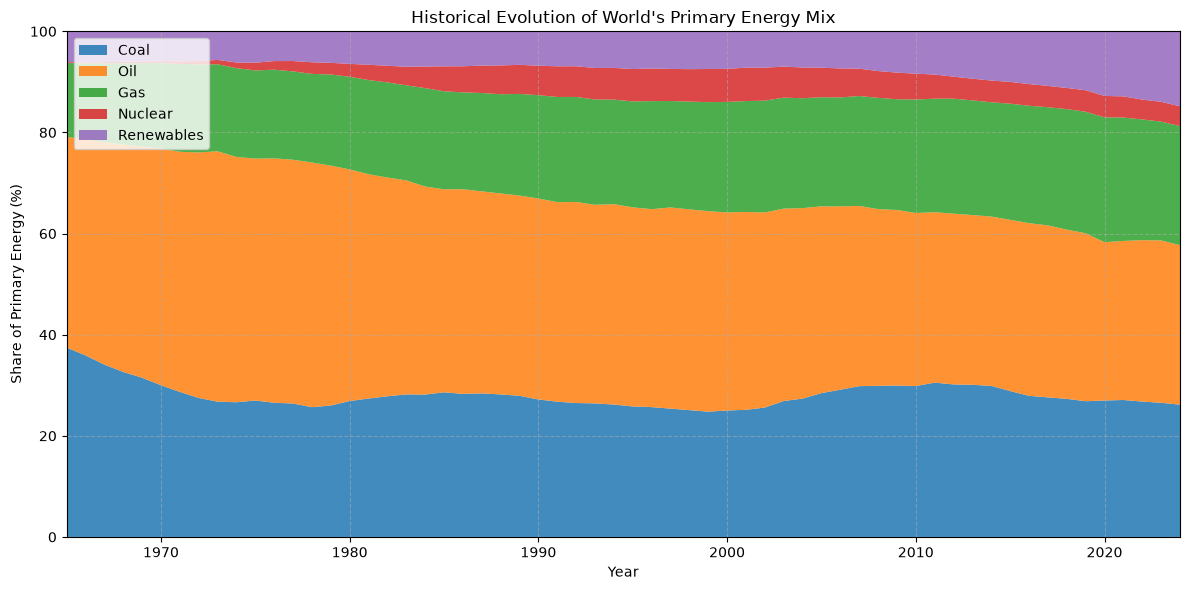

In [12]:
# Keep only years with complete information, dropping rows with missing values
# Prepare World energy mix data for the chart
# Plot the historical evolution of the global energy mix
fig = plots.plot_world_energy_mix(df_world)
plt.show()

In [13]:
#since the graph starts from about 1965, I'm checking if there is a problem in my code verifying if a random coluumn has values before 1965
for vrb in mix_columns:
    first_nm_year= df_world[df_world[vrb].notnull()]['year'].min()
    last_nm_year= df_world[df_world[vrb].notnull()]['year'].max()
    print(f"The first available year for {vrb} is: {first_nm_year}")
    print(f"The last available year for {vrb} is: {last_nm_year}")

The first available year for coal_share_energy is: 1965
The last available year for coal_share_energy is: 2024
The first available year for oil_share_energy is: 1965
The last available year for oil_share_energy is: 2024
The first available year for gas_share_energy is: 1965
The last available year for gas_share_energy is: 2024
The first available year for nuclear_share_energy is: 1965
The last available year for nuclear_share_energy is: 2024
The first available year for renewables_share_energy is: 1965
The last available year for renewables_share_energy is: 2024


Now I can say that there are no available values before 1965 and after 2024 so our analysis from now on would focus on that range. I can also see that the graph gives a general idea of the evolution in the usage of the considered energy sources. On the other hand I think it is not very clear, so I am going to aggregate the fossil sources and renewable sources (considering the nuclear as a different subset).

In [14]:
# Select the available macro-regions
df_regions = df_energy[
    df_energy["country"].isin(valid_regions)
].copy()

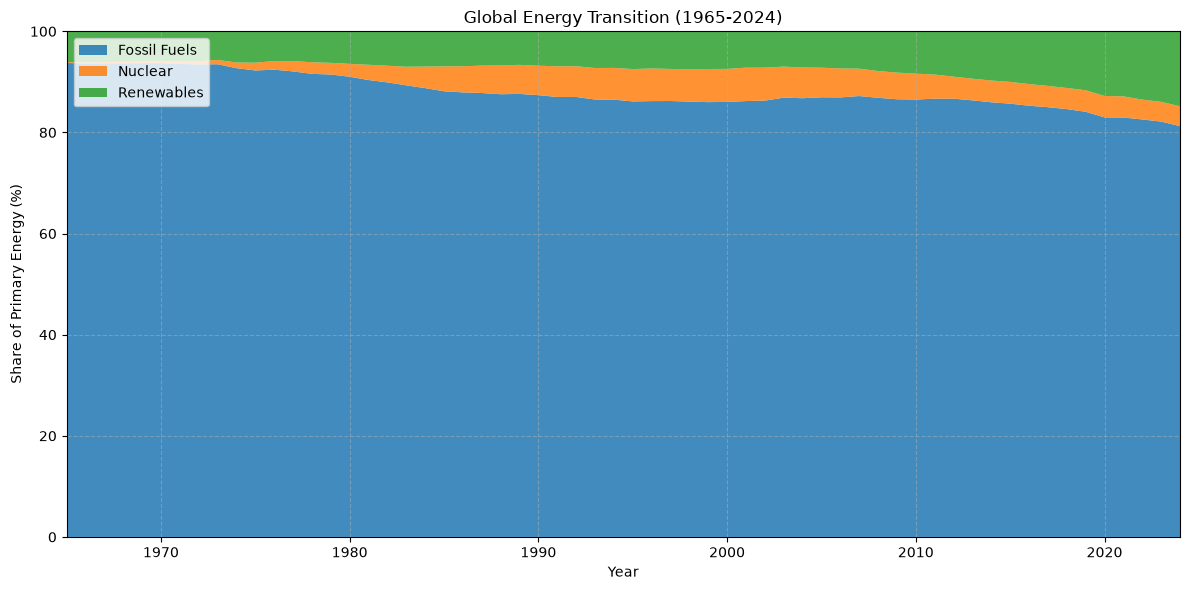

In [15]:
# Prepare World energy transition data
df_world_transition = analysis.prepare_world_energy_transition_data(df_regions)

#Plot the global energy transition
fig = plots.plot_world_energy_transition(df_world_transition)
plt.show()


Now we can clearly see how renewables have been constantly growing, especially in the last decade due to various reasons, such as laws, climate policies and cost reductions. nuclear energy consumption instead experienced its "boom" in the early 1980s but later stabilized and even reduced because of the Chernobyl disaster in 1986 alongside other challenges such as high building costs and radioactive waste management.

Moving forward, this analysis will primarily focus on Europe, North America and Asia. This selection is justified by their combined share of global primary energy consumption, which currently stands at approximately 91.5%.

Furthermore, Europe and North America have historically been the main drivers of industrialization and are now subject to strict environmental regulations. On the other hand, Asia has emerged as a major global player, accounting for the largest share of global energy demand while also leading worldwide investments in renewable energy infrastructure.

I will also examine the other continents to identify any distinctive trends or developments. For example, South America is expected to show a significant share of hydropower in its energy mix. However, given their relatively small contribution to global energy consumption, these regions will play a secondary role in the overall analysis.



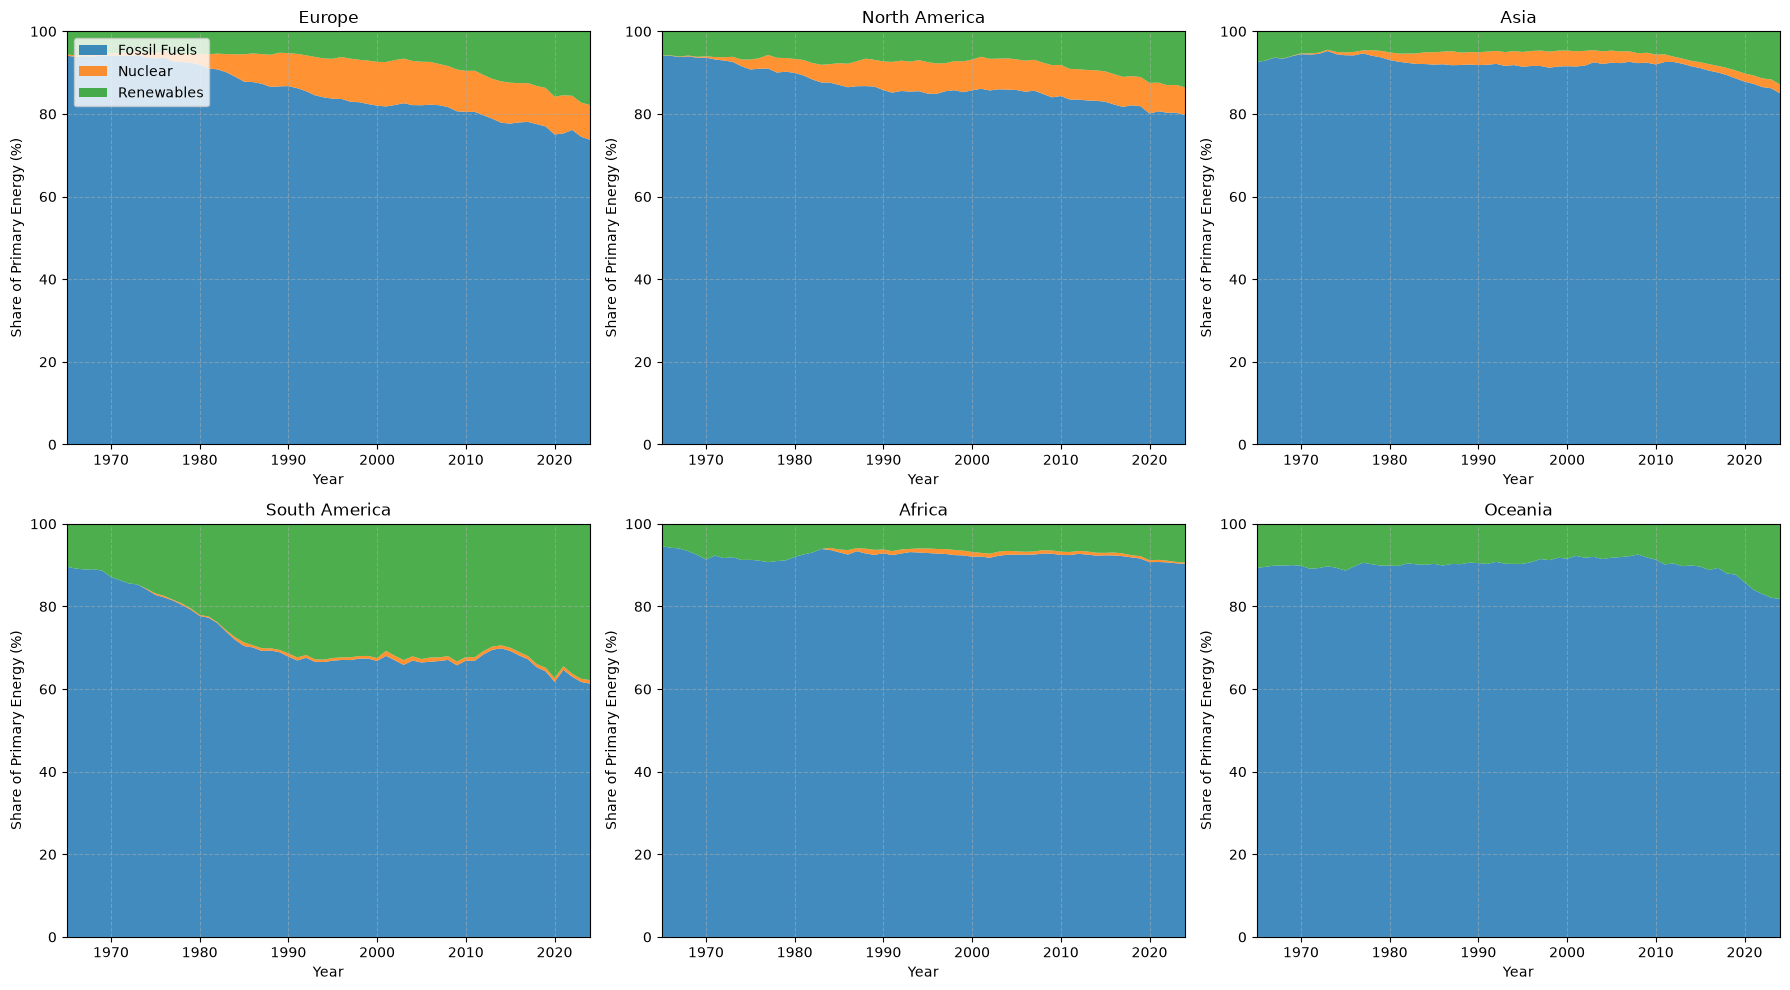

In [16]:
# Prepare regional energy mix data
df_regional_mix = analysis.prepare_regional_energy_mix_data(df_regions)

# Plot the energy mix across regions
fig = plots.plot_regional_energy_mix(df_regional_mix)
plt.show()



As illustrated from the data, from the early 1970s in Europe and North America and from the 1980s in Asia, the share of nuclear energy had been growing very fast until the mid 1980s. Following this period their growing rate decreased until the beginning of the new century where it stabilized and even got negative. The renewables instead, in all the 3 continents, mantained the same share for a very long period: from 1965 to about 2005 for Europe and North America and 2012 for Asia. After this period the renewables share experienced a constatly growing rate trough the end of the considered period (2025). 

As expected, South America presents a distinctive pattern: it has the largest renewables share among all the other continent, with a particularly rapid growth rate from 1970 to 1990. On the other hand Africa shows relatively stable shares in all the sources, while Oceania follows the trend of the Western continents. It is also worth noticing that Oceania presents a null share on nuclear energy.

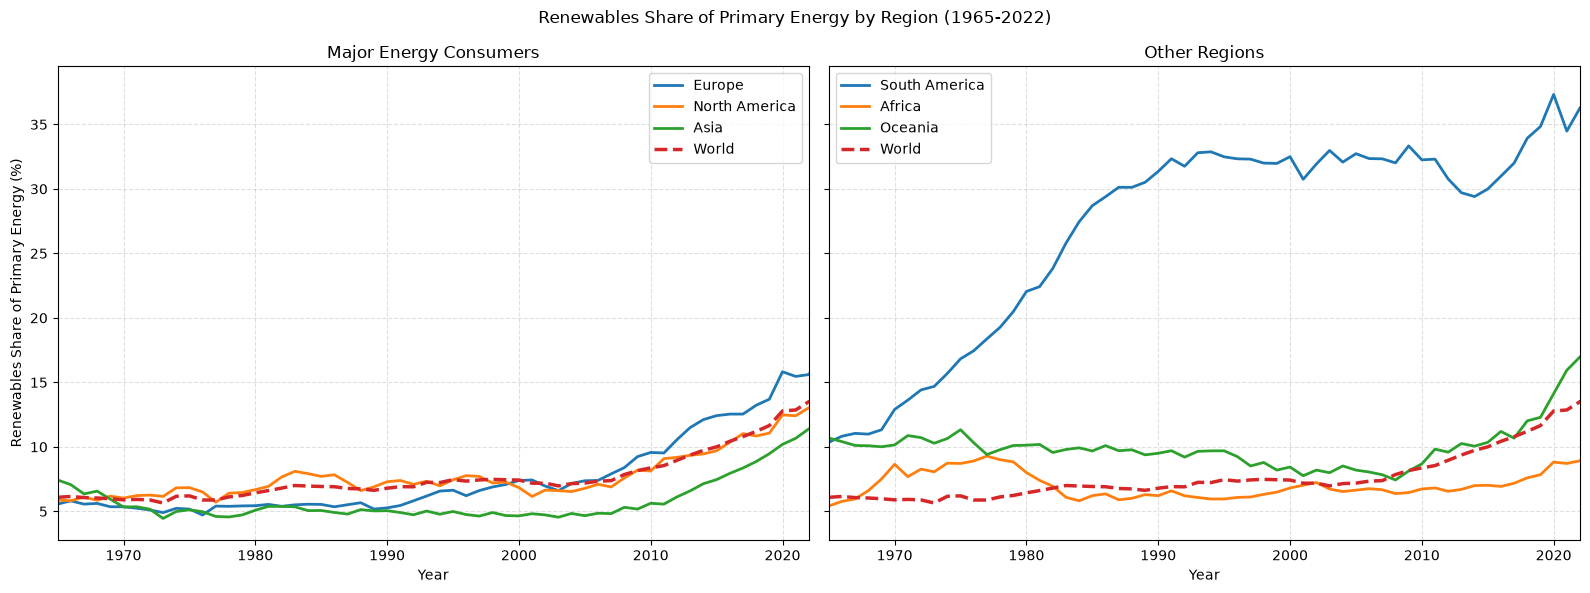

In [17]:
# Prepare regional data for renewables comparison
df_renewables = analysis.prepare_renewables_comparison_data(df_regions)

# Plot the comparison of renewable energy shares
fig = plots.plot_renewables_comparison(df_renewables)
plt.show()

The data show that North America (at least from the 1990s) has more or less followed the world trend in terms of renewable energy share. Europe has been below the World average until around 2000 when it inverted the trend, meanwhile Asia has always been way below from the late 1960s.

For the other regions, as already suggested by the previous graph, South America is the total leader in the renewables' share of primary energy consuption, while Oceania developed mostly from the late 2000s and Africa has only regitered a slight improvement in the latest period.







HOW CO₂ EMISSIONS RELATE TO GDP AND POPULATION

In [18]:
# Search for CO2-related variables in the Energy dataset
co2_columns = [
    col for col in df_energy.columns
    if 'co2' in col.lower() or 'carbon' in col.lower()
]

print("CO2-related variables found:", co2_columns)

# Search for greenhouse gas-related variables
greenhouse_columns = [
    col for col in df_energy.columns
    if 'greenhouse' in col.lower()
]

print("Greenhouse gas variables found:", greenhouse_columns)

CO2-related variables found: ['carbon_intensity_elec', 'low_carbon_cons_change_pct', 'low_carbon_cons_change_twh', 'low_carbon_consumption', 'low_carbon_elec_per_capita', 'low_carbon_electricity', 'low_carbon_energy_per_capita', 'low_carbon_share_elec', 'low_carbon_share_energy']
Greenhouse gas variables found: ['greenhouse_gas_emissions']


The Energy dataset contains several carbon related indicators, such as carbon intensity and low-carbon energy consumption. However, these variables do not directly measure total CO₂ emissions. In addiction I also found some greenhouse gasses related indicators but nothing specifically referred to CO₂. Therefore, to investigate the relationship between economic growth and CO₂ emissions, I decided to use the dedicated Our World in Data CO₂ dataset.

In [19]:
# Study the CO2 dataset
print("Dataset shape:", df_co2.shape)
print("\nDataset columns:")
print(df_co2.columns.tolist())
print("\nFirst five rows:")
print(df_co2.head())

Dataset shape: (56269, 79)

Dataset columns:
['country', 'year', 'iso_code', 'population', 'gdp', 'cement_co2', 'cement_co2_per_capita', 'co2', 'co2_growth_abs', 'co2_growth_prct', 'co2_including_luc', 'co2_including_luc_growth_abs', 'co2_including_luc_growth_prct', 'co2_including_luc_per_capita', 'co2_including_luc_per_gdp', 'co2_including_luc_per_unit_energy', 'co2_per_capita', 'co2_per_gdp', 'co2_per_unit_energy', 'coal_co2', 'coal_co2_per_capita', 'consumption_co2', 'consumption_co2_per_capita', 'consumption_co2_per_gdp', 'cumulative_cement_co2', 'cumulative_co2', 'cumulative_co2_including_luc', 'cumulative_coal_co2', 'cumulative_flaring_co2', 'cumulative_gas_co2', 'cumulative_luc_co2', 'cumulative_oil_co2', 'cumulative_other_co2', 'energy_per_capita', 'energy_per_gdp', 'flaring_co2', 'flaring_co2_per_capita', 'gas_co2', 'gas_co2_per_capita', 'ghg_excluding_lucf_per_capita', 'ghg_per_capita', 'land_use_change_co2', 'land_use_change_co2_per_capita', 'methane', 'methane_per_capita', 

In [20]:
# Check missing values in the main variables
print(df_co2[['co2', 'gdp', 'population']].isna().sum())

# Check the time range
print("First year:", df_co2['year'].min())
print("Last year:", df_co2['year'].max())

# Check data availability by decade
df_co2_check = df_co2.copy()
df_co2_check['decade'] = (df_co2_check['year'] // 10) * 10

print(
    df_co2_check.groupby('decade')[['co2', 'gdp', 'population']]
    .count()
)


co2           26050
gdp           40902
population    12145
dtype: int64
First year: 1750
Last year: 2025
         co2   gdp  population
decade                        
1750     160     0          96
1760     160     0          96
1770     160     0          96
1780     175     0          96
1790     206     0          97
1800     234     0         942
1810     241     0         948
1820     250   122         957
1830     346   121        1045
1840     311   135         991
1850     528   181        2093
1860     737   180        2096
1870     847   291        2096
1880     871   262        2096
1890     974   289        2096
1900    1016   379        2101
1910    1072   429        2099
1920    1168   501        2101
1930    1294   525        2100
1940    1335   480        2098
1950    2137  1459        2340
1960    2267  1471        2340
1970    2340  1495        2340
1980    2346  1626        2340
1990    2492  1639        2340
2000    2520  1641        2340
2010    2520  1646        

In [21]:
# Select the period from 1950 to 2022
recent_data = df_co2[
    (df_co2['year'] >= 1950) &
    (df_co2['year'] <= 2022)
].copy()

# Check missing values in the main variables
print(recent_data[['co2', 'gdp', 'population']].isna().sum())

# Check duplicate country-year observations
print("Duplicates:", df_co2.duplicated(
    subset=['country', 'year']
).sum())

# Count available observations
print("CO2:", recent_data['co2'].notna().sum())
print("GDP:", recent_data['gdp'].notna().sum())
print("Population:", recent_data['population'].notna().sum())

# Count observations with all three variables available
complete_data = recent_data.dropna(
    subset=['co2', 'gdp', 'population']
)

print("Complete observations:", len(complete_data))

co2           1463
gdp           7369
population    1759
dtype: int64
Duplicates: 0
CO2: 17378
GDP: 11472
Population: 17082
Complete observations: 11252


In [22]:
# Prepare the dataset for the CO2 analysis
df_co2_analysis = analysis.prepare_co2_analysis_data(df_co2)

# Check the resulting dataset
print("Dataset shape:", df_co2_analysis.shape)
print(df_co2_analysis.head())


Dataset shape: (18134, 5)
         country  year    co2           gdp  population
200  Afghanistan  1950  0.081  9.421400e+09   7776180.0
201  Afghanistan  1951  0.088  9.692280e+09   7879343.0
202  Afghanistan  1952  0.088  1.001732e+10   7987784.0
203  Afghanistan  1953  0.099  1.063052e+10   8096703.0
204  Afghanistan  1954  0.103  1.086636e+10   8207954.0


In [23]:
# controlling the previous code worked as wanted: expecting zero null values and 5 columns and time range from 1950 to 2022. Checking also how many countries are in the dataframe



print(df_co2_analysis.shape)

print(df_co2_analysis.isna().sum())

print("First year:", df_co2_analysis['year'].min())
print("Last year:", df_co2_analysis['year'].max())

print("Number of entities:",
      df_co2_analysis['country'].nunique())


(18134, 5)
country          0
year             0
co2              0
gdp           6882
population    1450
dtype: int64
First year: 1950
Last year: 2025
Number of entities: 252


In [24]:
# checking if 1950 is a suitable starting point for comparing
print(df_co2_analysis.groupby('year').size())

year
1950    208
1951    210
1952    211
1953    211
1954    212
       ... 
2021    252
2022    252
2023    252
2024    252
2025    252
Length: 76, dtype: int64


In [25]:
# Select global CO2 emissions
df_world_co2 = analysis.prepare_co2_data(df_co2_analysis)

# Checking the number and range of available observations
print("Number of observations:", len(df_world_co2))
print("Available years:")
print(df_world_co2["year"].tolist())

# Check the resulting dataset
print(df_world_co2.head())

Number of observations: 76
Available years:
[1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
      country  year       co2           gdp    population
55465   World  1950  5924.495  8.461552e+12  2.493093e+09
55466   World  1951  6378.455           NaN  2.536927e+09
55467   World  1952  6459.393           NaN  2.584086e+09
55468   World  1953  6640.496           NaN  2.634106e+09
55469   World  1954  6776.052           NaN  2.685895e+09


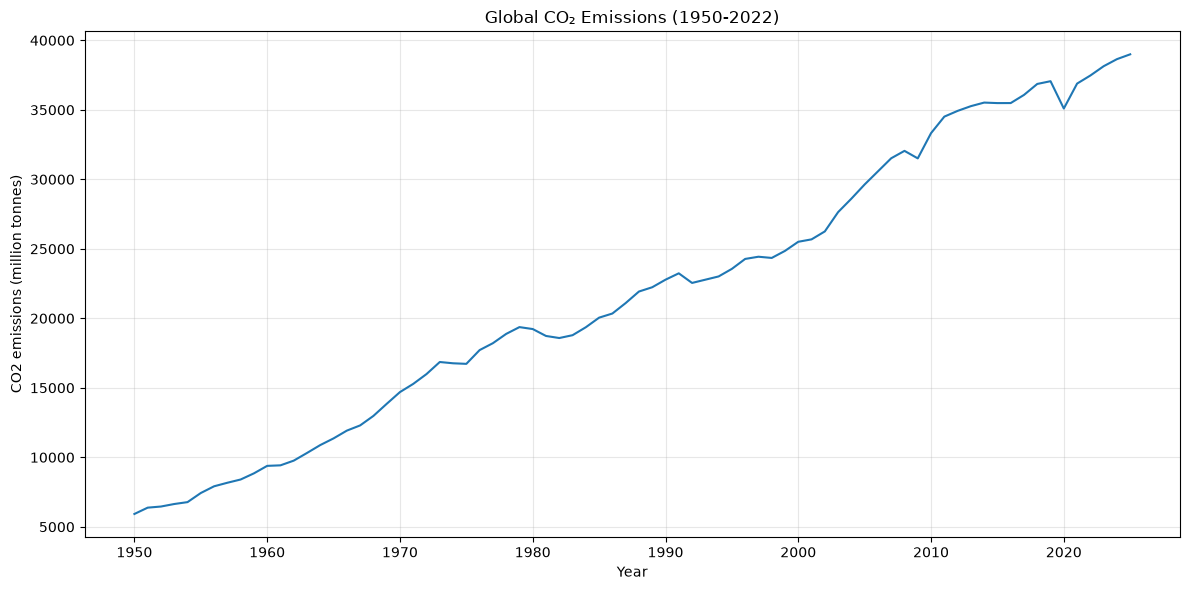

In [26]:
# Plot global CO2 emissions
fig = plots.plot_co2_emissions(df_world_co2)

Global CO₂ emissions generally increased between 1950 and 2022. Although the overall trend is clearly upward, the rate of growth varied across the decades. The most noticeable decline occurred in 2020, coinciding with the COVID-19 pandemic, after which emissions quickly rebounded. Another turning point is the beginning of the 2000s, when the slope of the line became steeper.

In [27]:
# Prepare regional CO2 data
df_co2_regions = analysis.prepare_co2_region_data(df_co2)

# Check data availability by region
df_co2_regions.groupby('country').agg(
    years_available=('year', 'count'),
    missing_co2=('co2', lambda x: round(x.isna().mean() * 100, 1)),
    missing_population=('population', lambda x: round(x.isna().mean() * 100, 1))
)

 

,years_available,missing_co2,missing_population
country,,,
Africa,73,0.0,0.0
Asia,73,0.0,0.0
Europe,73,0.0,0.0
North America,73,0.0,0.0
Oceania,73,0.0,0.0
South America,73,0.0,0.0
World,73,0.0,0.0


This is the best possible result for our analysis: there are available data for the aggregate continents with no missing data on "co2" and "population"

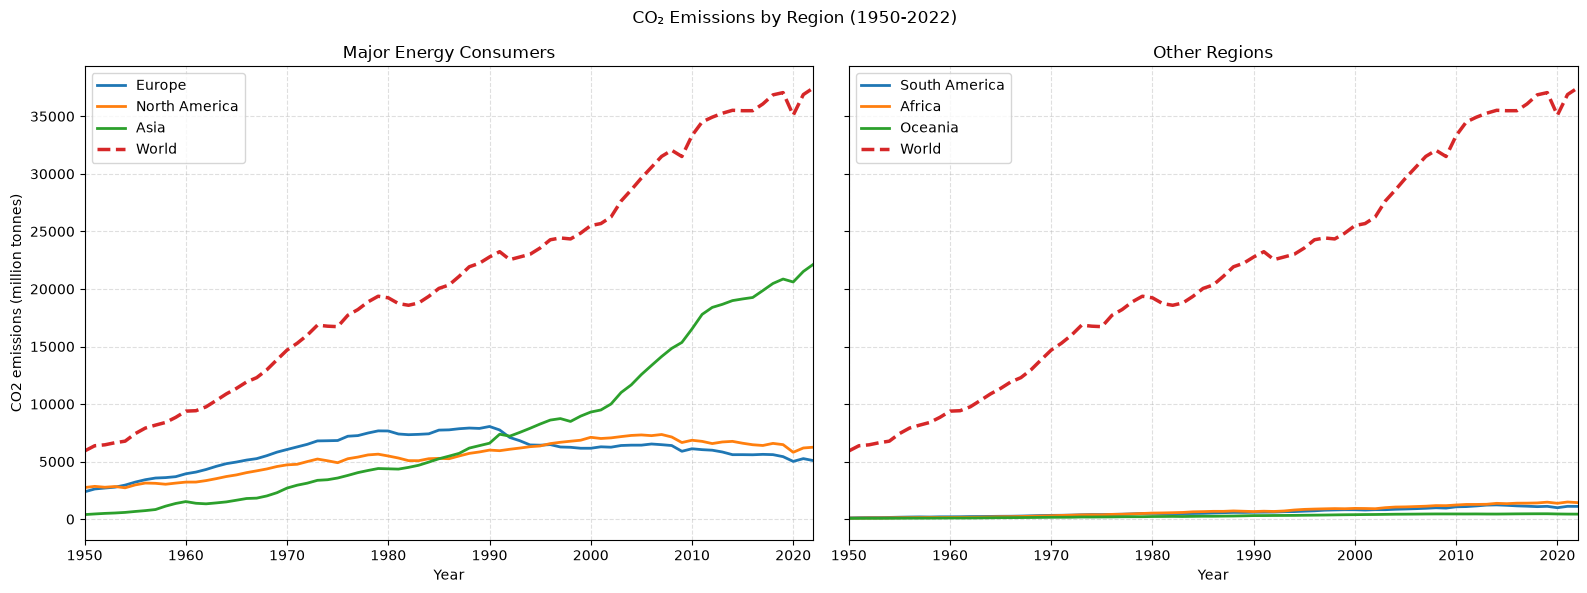

In [28]:
# Plot CO2 emissions by region
fig = plots.plot_co2_regions(
    df_co2_regions,
    [
        "Europe", "North America", "Asia",
        "South America", "Africa", "Oceania"
    ]
)

In the graph on the left, we can see how Europe and North America decreased or at least stabilized their emissions from the early 1990s, after growing in the previous period. Asia, on the other hand has been growing non-stop and even got a steeper emissions line fom the 2000s.

In the graph on the right, emissions from all the other regions have also increased over time. However, due to the shared vertical scale, their emission levels appear relatively close to zero when compared with those of the major emitting regions.

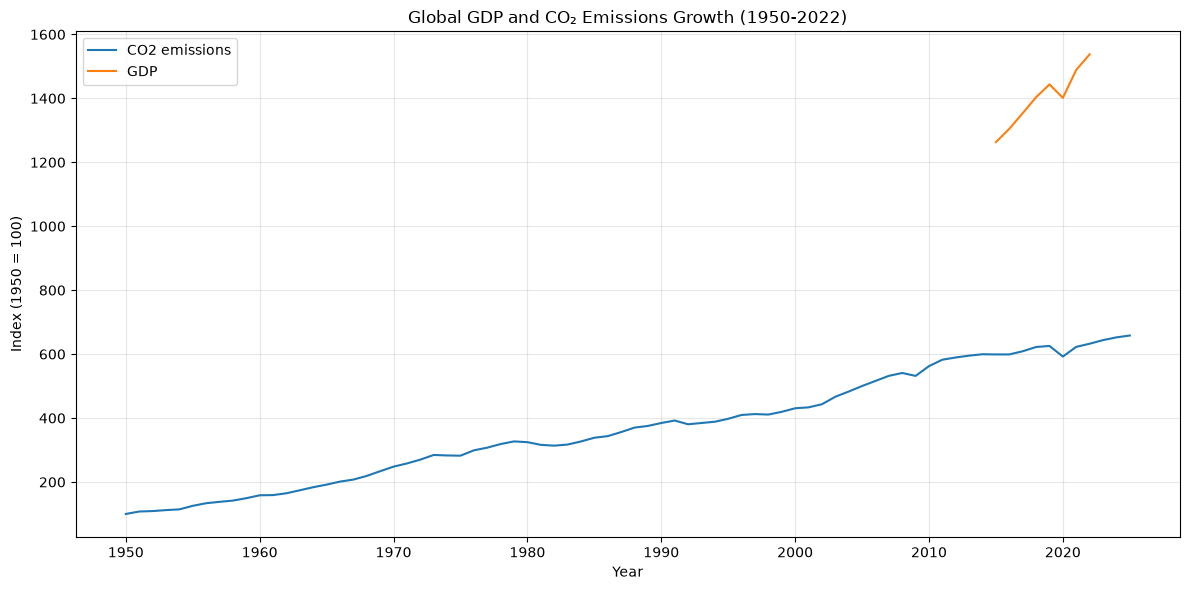

In [29]:
# Prepare GDP and CO2 indexes
df_world_co2 = analysis.prepare_gdp_vs_co2_data(df_world_co2)

# Plot global GDP and CO2 emissions growth
fig = plots.plot_gdp_vs_co2(df_world_co2)

GDP and CO₂ emissions follow a similar trend: both increase steadily until 2000, when their growth rate become snoticeably steeper.Both also experience a temporary decline in the COVID-19 period, followed by a quick rebound. Overall the GDP has a higher growth rate than CO₂ emissions suggesting a relative decoupling: the emissions have been growing but at a significantly slower rate than gdp

Correlation coefficient: 0.975
R-squared: 0.951


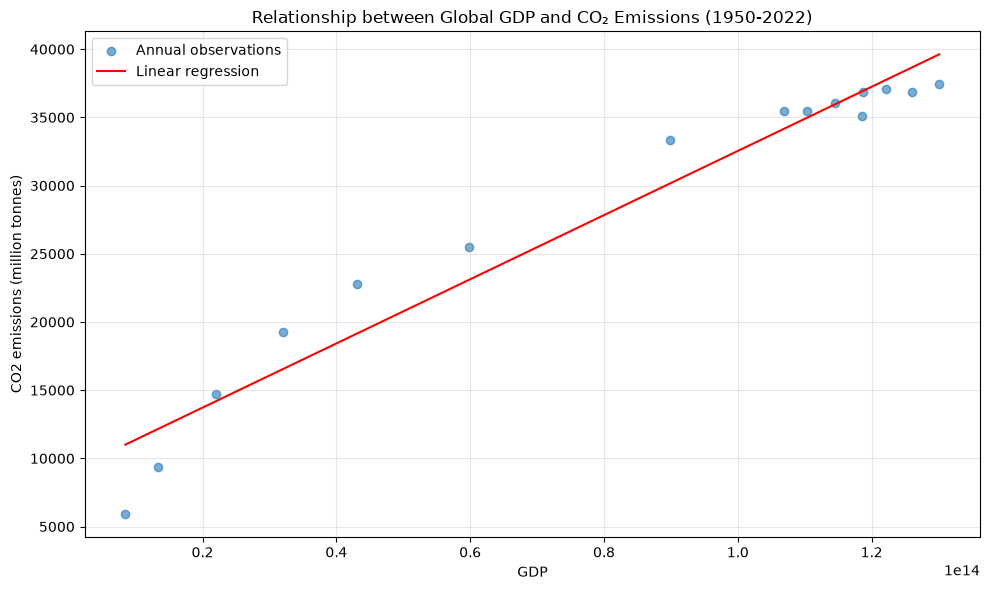

In [30]:
# Calculate global GDP-CO2 regression
regression_results = analysis.calculate_global_regression(df_world_co2)

# Plot global GDP-CO2 relationship
fig = plots.plot_global_gdp_co2_regression(
    df_world_co2,
    regression_results
)

# Compute correlation and R-squared
print("Correlation coefficient:", round(regression_results[4], 3))
print("R-squared:", round(regression_results[5], 3))

Overall, there appears to be a positive correlation between GDP and CO₂ emissions, confirmed by the correlation cofficient of 0,975.Furthermore, the R-squared value of 0.951 indicates that the linear regression model explains approximately 95.1% of the variation in CO₂ emissions. 

On the other hand, this strong correlation does not necessarily imply causation, as both variables have followed an upward trend over time. However, at higher GDP levels (corresponding to more recent years), CO₂ emissions appear to have grown at a significantly slower rate than GDP, suggesting a possible relative decoupling between economic growth and environmental impact. Nevertheless, this observation should be interpreted cautiously, as the high correlation coefficient may partly reflect the common upward trends of the two variables (growing up) rather than a direct economic relationship.

In [31]:
# Check the continent associated with an ISO country code ("ITA" should return "europe")
analysis.get_continent("ITA")

'Europe'

In [32]:
# Prepare country-level GDP and CO2 data with continent information
df_gdp_co2_countries, df_analysis = (
    analysis.prepare_country_continent_data(df_co2)
)

In [33]:
# Aggregate GDP, CO2 and population by continent and year
df_continents = analysis.aggregate_continent_data(df_analysis)

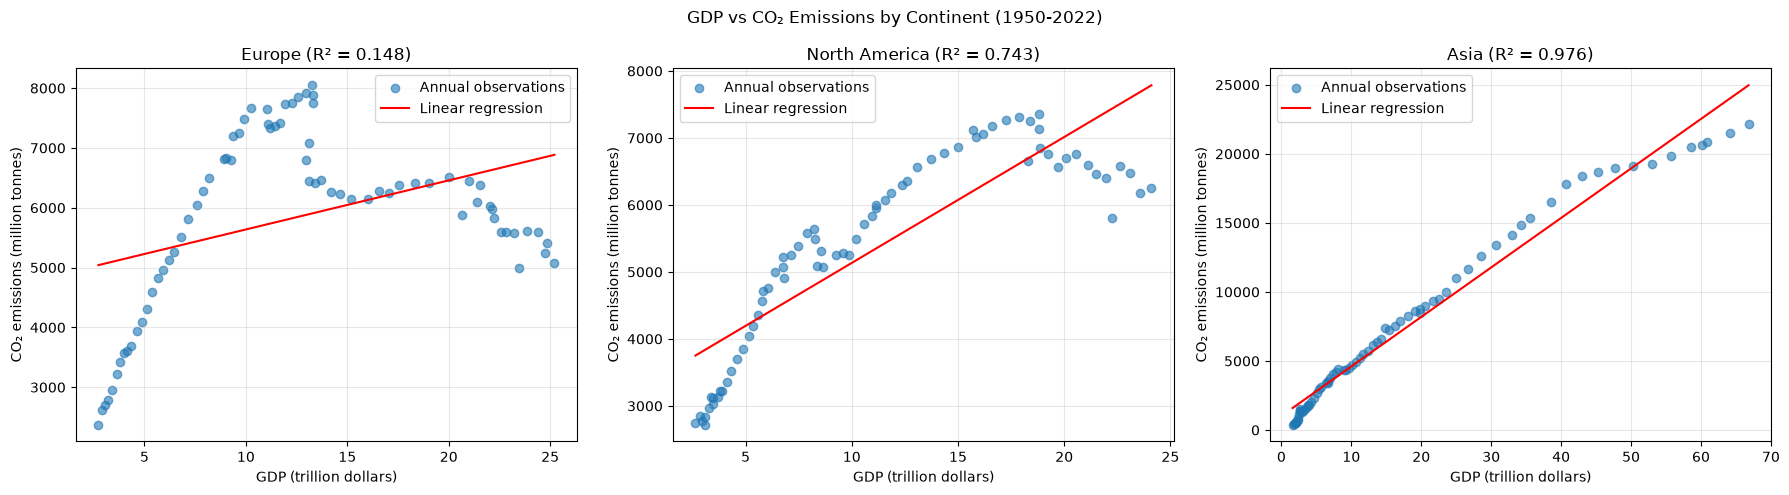

In [34]:
# Calculate GDP-CO2 regressions by continent
regression_results = analysis.calculate_continent_regressions(
    df_continents
)

# Plot continental GDP-CO2 regressions
fig = plots.plot_continent_gdp_co2_regressions(
    regression_results,
    ["Europe", "North America", "Asia"],
    "1950-2022"
)

The plots show three different situations:

Europe has a very low R² value, mainly because when GDP reaches approximately 13 trillion units, CO₂ emissions start decreasing despite the continued growth in GDP. This change in the relationship between the two variables makes it difficult for a single linear regression line to accurately describe the overall trend.

North America shows a similar situation, but the reversal in the trend occurs at a much higher GDP level (around 18 trillion units). Moreover, the observations are generally closer to the regression line compared to Europe, resulting in a higher R^2 value.

Asia, instead, shows a very strong linear relationship between GDP and CO₂ emissions. The observations remain very close to the regression line, suggesting that increases in GDP have been consistently associated with increases in CO₂ emissions throughout the period considered.

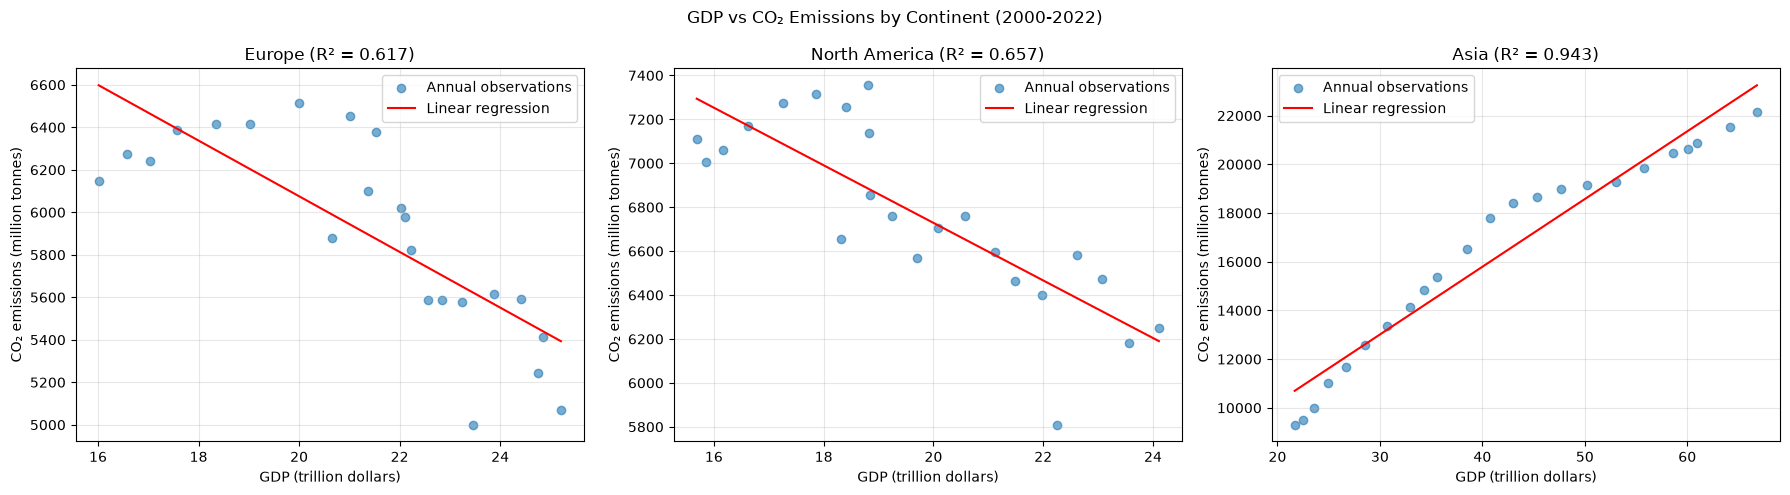

In [35]:
# Prepare continental data for the 2000-2022 period
recent_data = analysis.prepare_recent_continent_data(df_continents)

# Calculate GDP-CO2 regressions by continent
recent_regression_results = analysis.calculate_continent_regressions(
    recent_data
)

# Plot continental GDP-CO2 regressions
fig = plots.plot_continent_gdp_co2_regressions(
    recent_regression_results,
    ["Europe", "North America", "Asia"],
    "2000-2022"
)

As suggested by the previous plot, in more recent years there has been a reversal in the relationship between GDP and CO₂ emissions in Europe and North America. This is confirmed by the negative slopes of the regression lines. 

For Asia, instead, the positive relationship between GDP and emissions is confirmed.

These results may partly be explained by the strict environmental regulations implemented in Europe and North America, as well as by significant investments in sustainability and cleaner technologies, in addition to the transition to renewable sources.

In Asia, on the other hand, rapidly growing economies such as China and India may still show a positive relationship between GDP and emissions because economic growth has been largely driven by industrial production and other energy-intensive activities.

Furthermore, many companies have relocated their production activities to Asian countries, potentially shifting part of their carbon emissions from Western countries to Asia. This phenomenon is called carbon leakage.

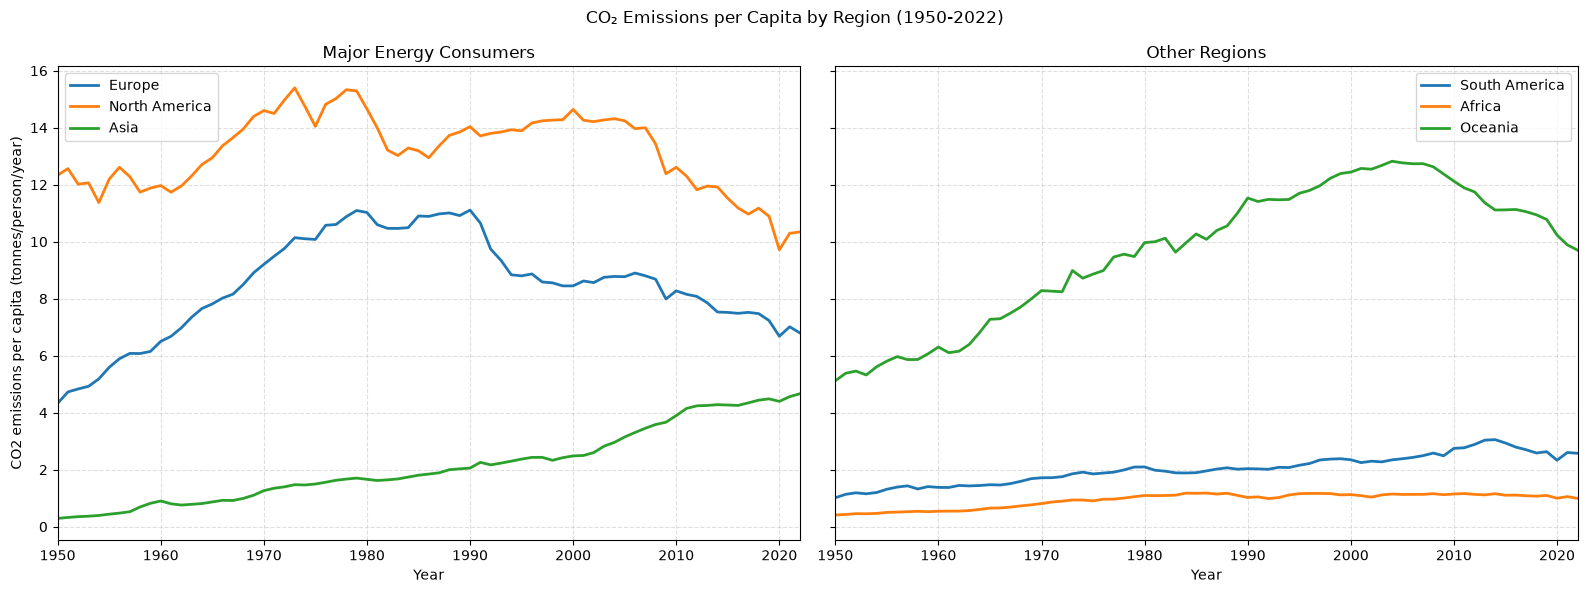

In [36]:
# Prepare regional CO2 emissions per capita data
df_co2_regions = analysis.prepare_per_capita_data(df_co2)

# Plot CO2 emissions per capita by region
fig = plots.plot_per_capita(
    df_co2_regions,
    [
        "Europe", "North America", "Asia",
        "South America", "Africa", "Oceania"
    ]
)

Analyzing emissions on a per capita basis provides a more nuanced and accurate perspective on the actual environmental footprint of these regions. Comparing aggregate emissions directly can be misleading, as it does not account for substantial demographic disparities across geographic areas. While absolute figures remain essential for assessing total atmospheric impact and identifying macro-trends, evaluating emissions relative to population size is crucial for contextualizing regional efficiency and lifestyle-driven consumption.

This adjustment reveals a critical insight that was not immediately evident from the aggregate emission plots: North America exhibits significantly higher per capita CO₂ emissions than both Europe and Major Asia. This suggests that, despite the progress made in reducing total emissions in recent decades, its average carbon footprint remains considerably higher. This may be partly explained by higher levels of energy consumption, car dependency, larger living spaces and consumption-intensive lifestyles. Therefore, although North America has achieved some degree of decoupling between economic growth and total emissions, its per capita environmental impact remains particularly high.